# Kepler Exoplanet Classification — Progress Report Notebook
**CMPS 261 · Track A (NASA Kepler Objects of Interest)**

Goal: predict whether a Kepler Object of Interest (KOI) is a real planet (CONFIRMED) or a FALSE POSITIVE, using only measurements available *before* scientists vetted it.

This notebook contains every experiment reported in the progress report:

| Notebook part | Report section |
|---|---|
| 1. Load and explore the data | 1. Problem Statement |
| 2. Leakage audit and preprocessing | 2. Data Preprocessing |
| 3. Grouped train/test split and metrics | 2–3. Splits and Evaluation Metrics |
| 4. Tuned classical baselines | 4. Classical Baseline |
| 5. MLP and ensemble | 5. Sophisticated Model |
| 6. Leakage and ablation experiments | 2 + Figure 1 |
| 7. Failure analysis, calibration, complexity | 6. Remaining Plan and Risks |
| 8. Save the trained models | (for the GitHub repo) |

**Data:** download the *KOI Table (Cumulative)* as CSV from the NASA Exoplanet Archive and save it as `data/kepler_cumulative.csv`.

Runtime: about 10–15 minutes on a laptop or Colab CPU (the random forest search is the slowest step).

In [1]:
# Uncomment on a fresh Colab runtime if xgboost is missing
# %pip install xgboost

In [2]:
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             brier_score_loss, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RS = 42                      # one random seed for every split and model -> reproducible results
DATA_PATH = "../data/kepler_cumulative.csv"

## 1. Load and explore the data
The archive CSV starts with comment lines beginning with `#`, so we skip them with `comment="#"`.

In [3]:
df = pd.read_csv(DATA_PATH, comment="#")
print("Rows (KOIs):", len(df), "| Columns:", df.shape[1])
print(df["koi_disposition"].value_counts())

Rows (KOIs): 9564 | Columns: 49
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2746
CANDIDATE         1979
Name: count, dtype: int64


**Label choice.** CANDIDATE objects have not been decided by scientists yet, so they have no ground truth.
We train and evaluate on **CONFIRMED (1) vs FALSE POSITIVE (0)** only and keep the CANDIDATEs aside to score later.

In [4]:
lab = df[df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
cand = df[df["koi_disposition"] == "CANDIDATE"].copy()
lab["y"] = (lab["koi_disposition"] == "CONFIRMED").astype(int)

print("Labelled objects:", len(lab), "| positive rate:", round(lab["y"].mean(), 3))
print("Held-out CANDIDATE objects:", len(cand))

Labelled objects: 7585 | positive rate: 0.362
Held-out CANDIDATE objects: 1979


## 2. Leakage audit and preprocessing

Some columns were created **after** scientists vetted the object, so they contain the answer:

- `koi_disposition`, `koi_pdisposition` — the label itself
- `koi_score` — the Robovetter's confidence score
- `koi_fpflag_nt`, `koi_fpflag_ss`, `koi_fpflag_co`, `koi_fpflag_ec` — false-positive flags set during vetting

We also drop identifiers and fields with no physical meaning for the task (`kepid`, names, delivery name, transit epoch, sky position).

Two subtler **process signals** are also excluded from the final feature set (Section 6 shows why):
- the number of KOIs on the same star (multi-planet systems were confirmed in bulk)
- missing-value indicators (objects with no transit fit are almost never confirmed)

In [5]:
LEAKY = ["koi_disposition", "koi_pdisposition", "koi_score",
         "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
IDS_AND_NONPHYSICAL = ["kepid", "kepoi_name", "kepler_name", "koi_tce_delivname",
                       "koi_time0bk", "koi_time0bk_err1", "koi_time0bk_err2", "ra", "dec"]

# Final (strict) feature set: 12 physical measurements
FEATS = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",   # transit / orbit
         "koi_prad", "koi_teq", "koi_insol",                                          # derived planet
         "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]                          # star

# Process signal kept only for the ablation in Section 6
for d in (lab, cand):
    d["n_koi_system"] = d["kepid"].map(df["kepid"].value_counts())

print("Share of rows with at least one missing feature:", round(lab[FEATS].isna().any(axis=1).mean(), 3))
lab[FEATS].isna().mean().round(3)

Share of rows with at least one missing feature: 0.034


koi_period       0.000
koi_duration     0.000
koi_depth        0.034
koi_impact       0.034
koi_model_snr    0.034
koi_prad         0.034
koi_teq          0.034
koi_insol        0.029
koi_steff        0.034
koi_slogg        0.034
koi_srad         0.034
koi_kepmag       0.000
dtype: float64

**Transforms.** Many features are heavily right-skewed (period, depth, SNR, radius...), so we take `log10` of them.
Missing values are filled with the median. Logistic regression and the MLP also need standardised inputs.
Everything is inside a scikit-learn `Pipeline`, so it is fitted on training folds only (no information from validation data leaks in).

In [6]:
LOG_COLS = ["koi_period", "koi_duration", "koi_depth", "koi_model_snr",
            "koi_prad", "koi_insol", "koi_srad", "koi_teq"]

def log_transform(X):
    X = X.copy()
    for c in LOG_COLS:
        if c in X:
            X[c] = np.log10(X[c].clip(lower=1e-3))   # clip avoids log(0)
    return X

def preprocessing(scale, missing_indicator=False):
    steps = [("log", FunctionTransformer(log_transform)),
             ("imp", SimpleImputer(strategy="median", add_indicator=missing_indicator))]
    if scale:
        steps.append(("sc", StandardScaler()))
    return steps

## 3. Grouped train/test split and evaluation metrics

Several KOIs can orbit the **same star** (`kepid`). If one is in training and another in testing, the model has already seen that star.
So every split is **grouped by star**:

- 20% held-out test set (grouped) — not used until the final report
- 5-fold `StratifiedGroupKFold` on the remaining 80% for tuning and validation

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RS)
tr_idx, te_idx = next(gss.split(lab, lab["y"], lab["kepid"]))
tr, te = lab.iloc[tr_idx], lab.iloc[te_idx]
print(f"Train/validation: {len(tr)} objects from {tr.kepid.nunique()} stars")
print(f"Held-out test:    {len(te)} objects from {te.kepid.nunique()} stars")
print("Stars in both:", len(set(tr.kepid) & set(te.kepid)))

y = tr["y"].values
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RS)
splits = list(cv.split(tr, y, tr["kepid"]))

Train/validation: 6041 objects from 5311 stars
Held-out test:    1544 objects from 1328 stars
Stars in both: 0


**Metrics**
- **PR-AUC (average precision)** — primary metric. Classes are imbalanced (36% positive) and the real task is *ranking* objects for follow-up.
- **Recall at 95% precision** — how many real planets we find if at most 1 in 20 flagged objects is a false alarm.
- **F1 at threshold 0.5**, **ROC-AUC** — for comparison with other work.
- **Brier score** + reliability curve — can the predicted probabilities be trusted?

All numbers are computed on **out-of-fold** predictions pooled over the 5 grouped folds.

In [8]:
def recall_at_precision(y_true, p, target=0.95):
    prec, rec, _ = precision_recall_curve(y_true, p)
    ok = rec[prec >= target]
    return float(ok.max()) if len(ok) else 0.0

def all_metrics(y_true, p):
    return {"PR-AUC": average_precision_score(y_true, p),
            "ROC-AUC": roc_auc_score(y_true, p),
            "F1@0.5": f1_score(y_true, p >= 0.5),
            "Recall@P95": recall_at_precision(y_true, p),
            "Brier": brier_score_loss(y_true, p)}

results, oof, best_models = {}, {}, {}

def tune_and_evaluate(name, pipe, param_space, n_iter=None, feats=FEATS):
    """Tune with grouped CV (maximising PR-AUC), then collect out-of-fold predictions of the best model."""
    X = tr[feats]
    if n_iter is None:
        search = GridSearchCV(pipe, param_space, scoring="average_precision", cv=splits, n_jobs=-1)
    else:
        search = RandomizedSearchCV(pipe, param_space, n_iter=n_iter, scoring="average_precision",
                                    cv=splits, n_jobs=-1, random_state=RS)
    t0 = time.time(); search.fit(X, y); tune_sec = time.time() - t0

    best = search.best_estimator_
    p = cross_val_predict(best, X, y, cv=splits, method="predict_proba")[:, 1]
    t0 = time.time(); best.fit(X, y); fit_sec = time.time() - t0

    m = all_metrics(y, p)
    m["PR-AUC fold SD"] = np.std([average_precision_score(y[v], p[v]) for _, v in splits])
    m["Configs tried"] = len(search.cv_results_["params"])
    m["Tuning time (s)"] = tune_sec
    m["Fit time (s)"] = fit_sec
    results[name], oof[name], best_models[name] = m, p, best
    print(name, "best params:", search.best_params_)
    print({k: round(v, 4) for k, v in m.items()})
    return best

## 4. Tuned classical baselines
Three classical models, same preprocessing, same folds, each tuned for PR-AUC.

In [9]:
lr = tune_and_evaluate(
    "Logistic regression",
    Pipeline(preprocessing(scale=True) + [("m", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
    {"m__C": [0.001, 0.01, 0.1, 1, 10, 100], "m__penalty": ["l2"]})

Logistic regression best params: {'m__C': 10, 'm__penalty': 'l2'}
{'PR-AUC': 0.7311, 'ROC-AUC': 0.8561, 'F1@0.5': 0.7161, 'Recall@P95': 0.0, 'Brier': 0.1584, 'PR-AUC fold SD': np.float64(0.0309), 'Configs tried': 6, 'Tuning time (s)': 2.6006, 'Fit time (s)': 0.0473}


In [10]:
rf = tune_and_evaluate(
    "Random forest",
    Pipeline(preprocessing(scale=False) + [("m", RandomForestClassifier(n_jobs=1, random_state=RS))]),
    {"m__n_estimators": [300, 600], "m__max_depth": [None, 10, 20],
     "m__min_samples_leaf": [1, 3, 5, 10], "m__max_features": ["sqrt", 0.5]},
    n_iter=20)

Random forest best params: {'m__n_estimators': 600, 'm__min_samples_leaf': 1, 'm__max_features': 'sqrt', 'm__max_depth': 20}
{'PR-AUC': 0.9451, 'ROC-AUC': 0.9716, 'F1@0.5': 0.8862, 'Recall@P95': 0.6687, 'Brier': 0.0627, 'PR-AUC fold SD': np.float64(0.0038), 'Configs tried': 20, 'Tuning time (s)': 281.196, 'Fit time (s)': 6.3534}


In [11]:
xgb = tune_and_evaluate(
    "XGBoost",
    Pipeline(preprocessing(scale=False) + [("m", XGBClassifier(eval_metric="logloss", n_jobs=1,
                                                               random_state=RS, tree_method="hist"))]),
    {"m__n_estimators": [200, 400, 800], "m__max_depth": [3, 4, 6, 8], "m__learning_rate": [0.02, 0.05, 0.1],
     "m__subsample": [0.7, 0.85, 1.0], "m__colsample_bytree": [0.6, 0.8, 1.0],
     "m__min_child_weight": [1, 3, 5], "m__reg_lambda": [0.5, 1, 5]},
    n_iter=40)

XGBoost best params: {'m__subsample': 1.0, 'm__reg_lambda': 5, 'm__n_estimators': 400, 'm__min_child_weight': 1, 'm__max_depth': 8, 'm__learning_rate': 0.05, 'm__colsample_bytree': 0.8}
{'PR-AUC': 0.9565, 'ROC-AUC': 0.9766, 'F1@0.5': 0.8976, 'Recall@P95': 0.748, 'Brier': 0.0555, 'PR-AUC fold SD': np.float64(0.0032), 'Configs tried': 40, 'Tuning time (s)': 45.481, 'Fit time (s)': 0.8317}


**Why logistic regression is so far behind:** the planet rate is not monotonic in the features.
Below we see that very weak *and* very strong signals are mostly false positives, which a single linear boundary cannot represent.

In [12]:
tmp = tr.assign(snr_bin=pd.cut(tr.koi_model_snr, [0, 10, 20, 50, 1e9], labels=["<10", "10-20", "20-50", ">50"]),
                prad_bin=pd.cut(tr.koi_prad, [0, 2, 4, 15, 1e9], labels=["<2", "2-4", "4-15", ">15 Earth radii"]))
display(tmp.groupby("snr_bin", observed=True)["y"].agg(["size", "mean"]).rename(columns={"mean": "planet rate"}).round(3))
display(tmp.groupby("prad_bin", observed=True)["y"].agg(["size", "mean"]).rename(columns={"mean": "planet rate"}).round(3))

,size,planet rate
snr_bin,,
<10,607,0.056
10-20,1428,0.403
20-50,1632,0.615
>50,2165,0.255


,size,planet rate
prad_bin,,
<2,2159,0.447
2-4,1383,0.682
4-15,550,0.431
>15 Earth radii,1741,0.011


## 5. Sophisticated model: MLP (+ ensemble)

A feed-forward neural network on the same 12 standardised features, with early stopping.
Expected advantage: trees split on one feature at a time, while false positives are often defined by **combinations**
(e.g. a planet-sized depth on a large star). An MLP learns smooth joint boundaries.

In [13]:
mlp = tune_and_evaluate(
    "MLP",
    Pipeline(preprocessing(scale=True) + [("m", MLPClassifier(max_iter=600, early_stopping=True,
                                                              validation_fraction=0.15, n_iter_no_change=25,
                                                              random_state=RS))]),
    {"m__hidden_layer_sizes": [(64,), (128, 64), (256, 128, 64), (64, 64)],
     "m__alpha": [1e-4, 1e-3, 1e-2, 1e-1], "m__learning_rate_init": [1e-3, 3e-3], "m__batch_size": [64, 256]},
    n_iter=20)

MLP best params: {'m__learning_rate_init': 0.003, 'm__hidden_layer_sizes': (256, 128, 64), 'm__batch_size': 256, 'm__alpha': 0.1}
{'PR-AUC': 0.952, 'ROC-AUC': 0.9741, 'F1@0.5': 0.8896, 'Recall@P95': 0.7393, 'Brier': 0.058, 'PR-AUC fold SD': np.float64(0.0026), 'Configs tried': 20, 'Tuning time (s)': 76.1401, 'Fit time (s)': 3.1567}


In [14]:
# Simple ensemble: average the XGBoost and MLP probabilities
oof["Ensemble (XGB + MLP)"] = (oof["XGBoost"] + oof["MLP"]) / 2
results["Ensemble (XGB + MLP)"] = all_metrics(y, oof["Ensemble (XGB + MLP)"])

# Do the two models make the same mistakes?
err_xgb = (oof["XGBoost"] >= 0.5) != y
err_mlp = (oof["MLP"] >= 0.5) != y
print("XGBoost errors:", err_xgb.sum(), "| MLP errors:", err_mlp.sum(), "| shared:", (err_xgb & err_mlp).sum())

summary = pd.DataFrame(results).T[["PR-AUC", "PR-AUC fold SD", "ROC-AUC", "F1@0.5", "Recall@P95", "Brier",
                                    "Tuning time (s)", "Fit time (s)"]]
summary.round(3)

XGBoost errors: 446 | MLP errors: 481 | shared: 301


,PR-AUC,PR-AUC fold SD,ROC-AUC,F1@0.5,Recall@P95,Brier,Tuning time (s),Fit time (s)
Logistic regression,0.731,0.031,0.856,0.716,0.000,0.158,2.601,0.047
Random forest,0.945,0.004,0.972,0.886,0.669,0.063,281.196,6.353
XGBoost,0.956,0.003,0.977,0.898,0.748,0.055,45.481,0.832
MLP,0.952,0.003,0.974,0.890,0.739,0.058,76.140,3.157
Ensemble (XGB + MLP),0.960,NaN,0.978,0.906,0.787,0.052,NaN,NaN


## 6. Leakage and ablation experiments
**(a) What happens if we keep the vetting columns?** This shows why they must be removed.

In [15]:
FLAGS = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
LEAKY_FEATS = FEATS + ["koi_score"] + FLAGS

leaky_xgb = Pipeline(preprocessing(scale=False) + [("m", XGBClassifier(eval_metric="logloss", n_jobs=1,
                                                                       random_state=RS, tree_method="hist"))])
leaky_xgb.set_params(**xgb.get_params())          # same tuned hyperparameters as the honest model
p_leak = cross_val_predict(leaky_xgb, tr[LEAKY_FEATS], y, cv=splits, method="predict_proba")[:, 1]
print("XGBoost WITH leaky columns, PR-AUC:", round(average_precision_score(y, p_leak), 3))

flags_only = Pipeline(preprocessing(scale=False) + [("m", LogisticRegression(max_iter=2000))])
p_flags = cross_val_predict(flags_only, tr[FLAGS], y, cv=splits, method="predict_proba")[:, 1]
print("Logistic regression on the 4 flags ONLY, PR-AUC:", round(average_precision_score(y, p_flags), 3))

XGBoost WITH leaky columns, PR-AUC: 0.998
Logistic regression on the 4 flags ONLY, PR-AUC: 0.965


**(b) Process signals.** These are not vetting outputs, but they track *how* objects were confirmed rather than the physics. This part takes a few extra minutes because each model is re-tuned.

In [16]:
print("Disposition share by multi-KOI star:")
multi = df.kepid.map(df.kepid.value_counts()) > 1
display(pd.crosstab(multi.rename("star has >1 KOI"), df.koi_disposition, normalize="index").round(3))

print("Disposition counts when koi_depth is missing:")
display(pd.crosstab(df.koi_depth.isna().rename("koi_depth missing"), df.koi_disposition))

Disposition share by multi-KOI star:


koi_disposition,CANDIDATE,CONFIRMED,FALSE POSITIVE
star has >1 KOI,,,
False,0.206,0.176,0.618
True,0.208,0.640,0.151


Disposition counts when koi_depth is missing:


koi_disposition,CANDIDATE,CONFIRMED,FALSE POSITIVE
koi_depth missing,,,
False,1875,2744,4582
True,104,2,257


In [17]:
# Re-tune each model WITH the process signals (KOIs per star, the pipeline's planet number,
# and missing-value indicators), using the same search spaces as above, then compare.
WITH_SIGNALS = FEATS + ["koi_tce_plnt_num", "n_koi_system"]
strict_results = {k: dict(v) for k, v in results.items()}
strict_oof, strict_models = dict(oof), dict(best_models)

spaces = {
    "Logistic regression": (LogisticRegression(max_iter=5000, class_weight="balanced"), True,
                            {"m__C": [0.001, 0.01, 0.1, 1, 10, 100], "m__penalty": ["l2"]}, None),
    "XGBoost": (XGBClassifier(eval_metric="logloss", n_jobs=1, random_state=RS, tree_method="hist"), False,
                {"m__n_estimators": [200, 400, 800], "m__max_depth": [3, 4, 6, 8], "m__learning_rate": [0.02, 0.05, 0.1],
                 "m__subsample": [0.7, 0.85, 1.0], "m__colsample_bytree": [0.6, 0.8, 1.0],
                 "m__min_child_weight": [1, 3, 5], "m__reg_lambda": [0.5, 1, 5]}, 40),
    "MLP": (MLPClassifier(max_iter=600, early_stopping=True, validation_fraction=0.15, n_iter_no_change=25, random_state=RS), True,
            {"m__hidden_layer_sizes": [(64,), (128, 64), (256, 128, 64), (64, 64)],
             "m__alpha": [1e-4, 1e-3, 1e-2, 1e-1], "m__learning_rate_init": [1e-3, 3e-3], "m__batch_size": [64, 256]}, 20),
}
ablation = {}
for name, (model, scale, space, n_iter) in spaces.items():
    tune_and_evaluate(name + " +signals", Pipeline(preprocessing(scale, missing_indicator=True) + [("m", model)]),
                      space, n_iter=n_iter, feats=WITH_SIGNALS)
    ablation[name] = {"With process signals": results[name + " +signals"]["PR-AUC"],
                      "Strict (reported)": strict_results[name]["PR-AUC"]}

# put the strict (reported) models back as the main results
results, oof, best_models = strict_results, strict_oof, strict_models
ablation_df = pd.DataFrame(ablation).T
ablation_df.round(3)

Logistic regression +signals best params: {'m__C': 10, 'm__penalty': 'l2'}
{'PR-AUC': 0.8645, 'ROC-AUC': 0.9166, 'F1@0.5': 0.7727, 'Recall@P95': 0.4246, 'Brier': 0.1191, 'PR-AUC fold SD': np.float64(0.0055), 'Configs tried': 6, 'Tuning time (s)': 0.4923, 'Fit time (s)': 0.0268}


XGBoost +signals best params: {'m__subsample': 0.85, 'm__reg_lambda': 1, 'm__n_estimators': 400, 'm__min_child_weight': 3, 'm__max_depth': 6, 'm__learning_rate': 0.05, 'm__colsample_bytree': 1.0}
{'PR-AUC': 0.9673, 'ROC-AUC': 0.9815, 'F1@0.5': 0.9074, 'Recall@P95': 0.7748, 'Brier': 0.0492, 'PR-AUC fold SD': np.float64(0.0031), 'Configs tried': 40, 'Tuning time (s)': 47.5597, 'Fit time (s)': 0.5598}


MLP +signals best params: {'m__learning_rate_init': 0.003, 'm__hidden_layer_sizes': (64,), 'm__batch_size': 64, 'm__alpha': 0.001}
{'PR-AUC': 0.9621, 'ROC-AUC': 0.979, 'F1@0.5': 0.9029, 'Recall@P95': 0.8108, 'Brier': 0.0511, 'PR-AUC fold SD': np.float64(0.0042), 'Configs tried': 20, 'Tuning time (s)': 89.5027, 'Fit time (s)': 0.781}


,With process signals,Strict (reported)
Logistic regression,0.864,0.731
XGBoost,0.967,0.956
MLP,0.962,0.952


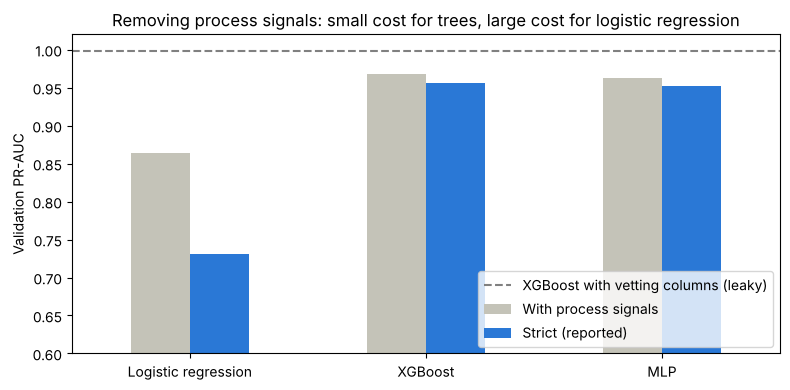

In [18]:
# Figure 1 of the progress report
ax = ablation_df.plot.bar(figsize=(8, 4), color=["#c4c3b8", "#2a78d6"], rot=0)
ax.axhline(average_precision_score(y, p_leak), ls="--", c="grey", label="XGBoost with vetting columns (leaky)")
ax.set_ylabel("Validation PR-AUC"); ax.set_ylim(0.6, 1.02); ax.legend(loc="lower right")
ax.set_title("Removing process signals: small cost for trees, large cost for logistic regression")
plt.tight_layout(); plt.savefig("figure1_ablation.png", dpi=200); plt.show()

## 7. Preliminary failure analysis, calibration and complexity
### 7.1 Where does XGBoost fail?
Error rate, false positives (FP), missed planets (FN) and PR-AUC inside each subgroup.

In [19]:
p = oof["XGBoost"]; pred = (p >= 0.5).astype(int)
fa = tr[FEATS].copy()
fa["y"], fa["p"], fa["err"] = y, p, (pred != y).astype(int)
fa["FP"] = ((y == 0) & (pred == 1)).astype(int)
fa["FN"] = ((y == 1) & (pred == 0)).astype(int)
fa["SNR"] = pd.cut(fa.koi_model_snr, [0, 10, 20, 50, 1e9], labels=["<10", "10-20", "20-50", ">50"])
fa["Planet radius"] = pd.cut(fa.koi_prad, [0, 1.25, 2, 4, 15, 1e9], labels=["<1.25", "1.25-2", "2-4", "4-15", ">15"])
fa["Star temperature"] = pd.cut(fa.koi_steff, [0, 4000, 5200, 6000, 6800, 1e9],
                                labels=["<4000K", "4000-5200", "5200-6000", "6000-6800", ">6800K"])
fa["Impact"] = pd.cut(fa.koi_impact, [-1, 0.5, 0.9, 1.0, 1e9], labels=["<0.5", "0.5-0.9", "0.9-1.0", ">1 (grazing)"])
fa["Has missing value"] = tr[FEATS].isna().any(axis=1).values

def subgroup_table(col):
    g = fa.groupby(col, observed=True)
    out = pd.DataFrame({"n": g.size(), "planet rate": g.y.mean(), "error rate": g.err.mean(),
                        "FP": g.FP.sum(), "FN": g.FN.sum()})
    out["PR-AUC"] = g.apply(lambda d: average_precision_score(d.y, d.p) if 0 < d.y.sum() < len(d) else np.nan)
    return out.round(3)

print(f"Total: {len(fa)} objects, {fa.FP.sum()} false alarms, {fa.FN.sum()} missed planets")
for col in ["SNR", "Planet radius", "Star temperature", "Impact", "Has missing value"]:
    print("\n==", col); display(subgroup_table(col))

Total: 6041 objects, 233 false alarms, 213 missed planets

== SNR


,n,planet rate,error rate,FP,FN,PR-AUC
SNR,,,,,,
<10,607,0.056,0.061,6,31,0.305
10-20,1428,0.403,0.141,113,89,0.899
20-50,1632,0.615,0.081,76,57,0.971
>50,2165,0.255,0.033,38,34,0.979



== Planet radius


,n,planet rate,error rate,FP,FN,PR-AUC
Planet radius,,,,,,
<1.25,1024,0.312,0.115,52,66,0.900
1.25-2,1135,0.569,0.125,83,59,0.944
2-4,1383,0.682,0.076,67,38,0.981
4-15,550,0.431,0.113,31,31,0.938
>15,1741,0.011,0.010,0,17,0.442



== Star temperature


,n,planet rate,error rate,FP,FN,PR-AUC
Star temperature,,,,,,
<4000K,197,0.579,0.061,9,3,0.984
4000-5200,1016,0.459,0.083,50,34,0.956
5200-6000,2686,0.429,0.081,117,101,0.963
6000-6800,1661,0.258,0.074,54,69,0.930
>6800K,273,0.018,0.026,3,4,0.305



== Impact


,n,planet rate,error rate,FP,FN,PR-AUC
Impact,,,,,,
<0.5,2557,0.472,0.090,130,101,0.960
0.5-0.9,1720,0.424,0.085,74,72,0.965
0.9-1.0,582,0.366,0.095,29,26,0.921
>1 (grazing),974,0.014,0.012,0,12,0.410



== Has missing value


,n,planet rate,error rate,FP,FN,PR-AUC
Has missing value,,,,,,
False,5832,0.371,0.076,233,211,0.957
True,209,0.010,0.010,0,2,0.261


In [20]:
# False positives that look like planets: compare medians of each outcome group
cols = ["koi_prad", "koi_depth", "koi_model_snr", "koi_impact", "koi_period", "koi_duration"]
groups = {"False alarm (FP)": fa.FP == 1, "Missed planet (FN)": fa.FN == 1,
          "Found planet (TP)": (fa.y == 1) & (pred == 1), "Rejected FP (TN)": (fa.y == 0) & (pred == 0)}
pd.DataFrame({k: fa.loc[m, cols].median() for k, m in groups.items()}).T.round(2)

,koi_prad,koi_depth,koi_model_snr,koi_impact,koi_period,koi_duration
False alarm (FP),1.75,312.50,19.80,0.41,7.87,3.22
Missed planet (FN),1.65,247.50,17.20,0.53,5.94,2.96
Found planet (TP),2.18,472.15,30.15,0.40,11.42,3.49
Rejected FP (TN),15.15,654.00,38.10,0.69,4.82,4.12


### 7.2 Calibration — can the probabilities be trusted?

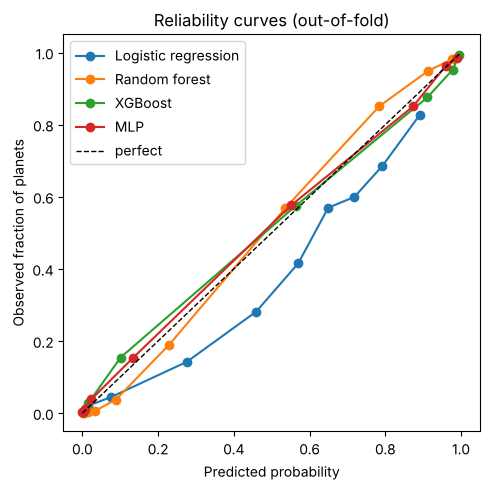

In [21]:
fig, ax = plt.subplots(figsize=(5, 5))
for name in ["Logistic regression", "Random forest", "XGBoost", "MLP"]:
    frac_pos, mean_pred = calibration_curve(y, oof[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed fraction of planets"); ax.legend()
ax.set_title("Reliability curves (out-of-fold)")
plt.tight_layout(); plt.savefig("figure2_calibration.png", dpi=200); plt.show()

### 7.3 Feature importance and complexity

In [22]:
xgb_gain = pd.Series(xgb.named_steps["m"].feature_importances_, index=FEATS).sort_values(ascending=False)
perm = permutation_importance(xgb, tr[FEATS], y, scoring="average_precision", n_repeats=5, random_state=RS, n_jobs=-1)
perm = pd.Series(perm.importances_mean, index=FEATS).sort_values(ascending=False)
pd.DataFrame({"XGB gain": xgb_gain, "Permutation (PR-AUC drop)": perm}).round(3)

,XGB gain,Permutation (PR-AUC drop)
koi_depth,0.058,0.010
koi_duration,0.061,0.054
koi_impact,0.057,0.019
koi_insol,0.115,0.001
koi_kepmag,0.022,0.002
koi_model_snr,0.125,0.076
koi_period,0.127,0.037
koi_prad,0.257,0.067
koi_slogg,0.037,0.001
koi_srad,0.038,0.008


In [23]:
def n_params(name):
    m = best_models[name].named_steps["m"]
    if name == "Logistic regression": return m.coef_.size + m.intercept_.size
    if name == "MLP": return sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    if name == "XGBoost": return f"{m.get_booster().num_boosted_rounds()} trees"
    return f"{len(m.estimators_)} trees"

rows = []
for name in ["Logistic regression", "Random forest", "XGBoost", "MLP"]:
    t0 = time.time()
    for _ in range(20): best_models[name].predict_proba(tr[FEATS])
    infer_us = (time.time() - t0) / 20 / len(tr) * 1e6
    rows.append({"Model": name, "PR-AUC": results[name]["PR-AUC"], "Size": n_params(name),
                 "Tuning time (s)": results[name]["Tuning time (s)"], "Fit time (s)": results[name]["Fit time (s)"],
                 "Inference (µs/object)": infer_us})
pd.DataFrame(rows).set_index("Model").round(3)

,PR-AUC,Size,Tuning time (s),Fit time (s),Inference (µs/object)
Model,,,,,
Logistic regression,0.731,13,2.601,0.047,1.057
Random forest,0.945,600 trees,281.196,6.353,44.021
XGBoost,0.956,400 trees,45.481,0.832,8.389
MLP,0.952,44545,76.140,3.157,3.222


## 8. Save the trained models and results
The held-out test set (`te`) is **not** evaluated yet; that happens once, for the final report.

In [24]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(best_models["XGBoost"], "models/xgboost_pipeline.joblib")
joblib.dump(best_models["MLP"], "models/mlp_pipeline.joblib")
pd.DataFrame(results).T.to_csv("validation_results.csv")
print("Saved models/ and validation_results.csv")

# How to use a saved model on new data:
# model = joblib.load("models/xgboost_pipeline.joblib")
# probs = model.predict_proba(new_df[FEATS])[:, 1]

Saved models/ and validation_results.csv
